In [1]:
import html
import re
import time
from dataclasses import dataclass
from datetime import datetime
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader
from torchmetrics.classification import MulticlassPrecision, MulticlassRecall

from mlkit.blocks.attention import SelfAttentionConfig
from mlkit.blocks.embeddings import LearnedPositions, TokenEmbeddingConfig
from mlkit.blocks.linear import LinearBlockConfig
from mlkit.blocks.transformer import TransformerEncoderBlockConfig
from mlkit.core.callbacks import EarlyStopping, MLflowLogger, ModelCheckpoint, ProgressLogger
from mlkit.core.history import History
from mlkit.core.schedulers import WarmupCosineLR
from mlkit.core.trainer import Trainer
from mlkit.data.splitter import StratifiedSplitter
from mlkit.data.subsets import TransformSubset
from mlkit.data.text import PadCollate, TextDataset, TextEncoder, Vocabulary, WordTokenizer
from mlkit.metrics.collections import multiclass_metrics
from mlkit.models.transformers import TransformerClassifier, TransformerClassifierConfig
from mlkit.tasks.classification import ClassificationTask
from mlkit.utils.logs import setup_logging
from mlkit.utils.seed import seed_everything
from mlkit.utils.tracking import flatten_params, setup_mlflow
from mlkit.visual.attention import plot_attention
from mlkit.visual.confusion import confusion_matrix, plot_confusion_matrix
from mlkit.visual.curves import plot_comparison
from mlkit.visual.saver import FigureSaver
from mlkit.visual.style import use_style

import mlflow

setup_logging()
use_style()

ROOT = Path("../..")
DATA_DIR = ROOT / "datasets/raw/ag_news"
setup_mlflow(ROOT, "lab3.2")

SEED = 42
SEEDS = (42, 43, 44)
TRAIN_SIZES = (1000, 4000, 8000)
VAL_SIZE = 2000

MAX_LEN = 64
MIN_FREQ = 2
MAX_VOCAB = 10_000

D_MODEL = 64
NUM_HEADS = 4
NUM_LAYERS = 2
FF_DIM = 128
HEAD_HIDDEN = 32
DROPOUT = 0.1

BATCH_SIZE = 32
EPOCHS = 30
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-2
WARMUP_EPOCHS = 1
MAX_GRAD_NORM = 1.0
PATIENCE = 5

ERRORS_SHOWN = 10
ATTENTION_TOKENS = 20

RUN_NAME = f"lab3.2_{datetime.now():%Y%m%d_%H%M%S}"
saver = FigureSaver(Path("artifacts") / RUN_NAME)

In [2]:
def clean(text: str) -> str:
    text = text.replace("\\", " ")
    text = re.sub(r"#(\d+);", r"&#\1;", text)
    text = html.unescape(text)
    text = re.sub(r"<[^>]+>", " ", text)
    return re.sub(r"\s+", " ", text).strip()


def load(path: Path) -> pd.DataFrame:
    frame = pd.read_csv(path, header=None, names=["label", "title", "description"])
    return pd.DataFrame({
        "text": (frame["title"] + " " + frame["description"]).map(clean),
        "label": frame["label"] - 1,
    })


train_df = load(DATA_DIR / "train.csv")
test_df = load(DATA_DIR / "test.csv")
class_names = (DATA_DIR / "classes.txt").read_text(encoding="utf-8").split()

for label, name in enumerate(class_names):
    print(f"[{name}] {train_df.loc[train_df['label'] == label, 'text'].iloc[0]}")

counts = pd.DataFrame(
    {
        "train": train_df["label"].value_counts().sort_index().to_numpy(),
        "test": test_df["label"].value_counts().sort_index().to_numpy(),
    },
    index=class_names,
)
counts.loc["total"] = counts.sum()
counts

[World] Venezuelans Vote Early in Referendum on Chavez Rule (Reuters) Reuters - Venezuelans turned out early and in large numbers on Sunday to vote in a historic referendum that will either remove left-wing President Hugo Chavez from office or give him a new mandate to govern for the next two years.
[Sports] Phelps, Thorpe Advance in 200 Freestyle (AP) AP - Michael Phelps took care of qualifying for the Olympic 200-meter freestyle semifinals Sunday, and then found out he had been added to the American team for the evening's 400 freestyle relay final. Phelps' rivals Ian Thorpe and Pieter van den Hoogenband and teammate Klete Keller were faster than the teenager in the 200 free preliminaries.
[Business] Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling band of ultra-cynics, are seeing green again.
[Sci/Tech] 'Madden,' 'ESPN' Football Score in Different Ways (Reuters) Reuters - Was absenteeism a little high on Tuesday among the guys at the 

,train,test
World,30000,1900
Sports,30000,1900
Business,30000,1900
Sci/Tech,30000,1900
total,120000,7600


Tokens per text: mean 44.8, median 44, p95 64, max 211
Texts longer than MAX_LEN = 64: 4.82%


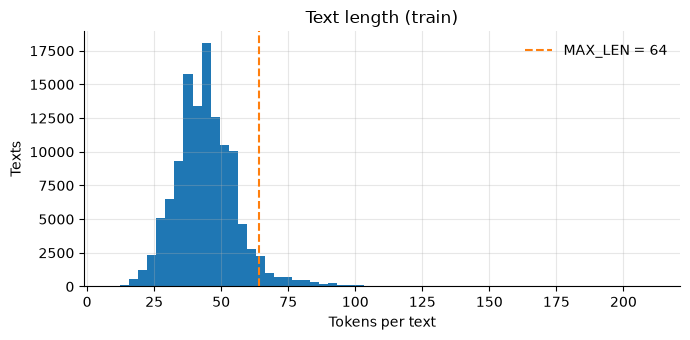

In [3]:
tokenizer = WordTokenizer()
lengths = train_df["text"].map(lambda text: len(tokenizer(text)))
print(
    f"Tokens per text: mean {lengths.mean():.1f}, median {lengths.median():.0f}, "
    f"p95 {lengths.quantile(0.95):.0f}, max {lengths.max()}"
)
print(f"Texts longer than MAX_LEN = {MAX_LEN}: {(lengths > MAX_LEN).mean():.2%}")

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(lengths, bins=60)
ax.axvline(MAX_LEN, color="C1", linestyle="--", label=f"MAX_LEN = {MAX_LEN}")
ax.set_xlabel("Tokens per text")
ax.set_ylabel("Texts")
ax.set_title("Text length (train)")
ax.legend()
fig.tight_layout()
saver.save(fig, "text_lengths");

In [4]:
train_labels: list[int] = train_df["label"].tolist()
increments = np.diff((0, *TRAIN_SIZES))
fractions = tuple(int(count) / len(train_labels) for count in (*increments, VAL_SIZE))
*parts, val_indices, _ = StratifiedSplitter((*fractions, 1 - sum(fractions)), seed=SEED).split(train_labels)
train_indices = {size: [index for part in parts[: k + 1] for index in part] for k, size in enumerate(TRAIN_SIZES)}

train_dataset = TextDataset(train_df["text"].tolist(), train_labels)
test_dataset = TextDataset(test_df["text"].tolist(), test_df["label"].tolist())
test_indices = list(range(len(test_dataset)))


def class_counts(indices: list[int], labels: list[int]) -> np.ndarray:
    return np.bincount([labels[index] for index in indices], minlength=len(class_names))


pd.DataFrame(
    {f"train {size}": class_counts(indices, train_labels) for size, indices in train_indices.items()}
    | {"val": class_counts(val_indices, train_labels), "test": class_counts(test_indices, test_dataset.labels)},
    index=class_names,
)

,train 1000,train 4000,train 8000,val,test
World,250,1000,2000,500,1900
Sports,250,1000,2000,500,1900
Business,250,1000,2000,500,1900
Sci/Tech,250,1000,2000,500,1900


In [5]:
def build_encoder(texts: list[str]) -> TextEncoder:
    vocabulary = Vocabulary(min_freq=MIN_FREQ, max_size=MAX_VOCAB)
    vocabulary.fill(tokenizer(text) for text in texts)
    return TextEncoder(tokenizer, vocabulary, MAX_LEN)


def make_loader(dataset: TextDataset, indices: list[int], encoder: TextEncoder, shuffle: bool = False) -> DataLoader:
    return DataLoader(
        TransformSubset(dataset, indices, encoder),
        batch_size=BATCH_SIZE if shuffle else 4 * BATCH_SIZE,
        shuffle=shuffle,
        collate_fn=PadCollate(encoder.vocabulary.pad_id),
    )


def unknown_share(encoder: TextEncoder, texts: list[str]) -> float:
    encoded = [encoder(text) for text in texts]
    unknown = sum(int((ids == encoder.vocabulary.unk_id).sum()) for ids in encoded)
    return unknown / sum(len(ids) for ids in encoded)


encoders = {size: build_encoder([train_dataset.texts[index] for index in indices]) for size, indices in train_indices.items()}
val_texts = [train_dataset.texts[index] for index in val_indices]

pd.DataFrame({
    f"train {size}": {
        "vocabulary size": len(encoder.vocabulary),
        "unknown tokens in val": unknown_share(encoder, val_texts),
    }
    for size, encoder in encoders.items()
}).T.round(4)

,vocabulary size,unknown tokens in val
train 1000,3949.0,0.1681
train 4000,9282.0,0.0754
train 8000,10000.0,0.0638


In [6]:
encoder = encoders[TRAIN_SIZES[-1]]
sample = train_dataset.texts[train_indices[TRAIN_SIZES[-1]][0]]
sample_ids = encoder(sample)
print("Text:", sample)
print("Ids:", sample_ids.tolist())
print("Decoded:", encoder.vocabulary.decode(sample_ids.tolist()))
print("Most frequent tokens:", encoder.vocabulary.decode(range(2, 22)))

ids, labels = next(iter(make_loader(train_dataset, train_indices[TRAIN_SIZES[-1]], encoder, shuffle=True)))
padding = (ids == encoder.vocabulary.pad_id).float().mean().item()
print(f"Batch: ids {tuple(ids.shape)} {ids.dtype} | labels {tuple(labels.shape)} | padding share {padding:.1%}")

Text: New Orleans Urges People to Take Shelter NEW ORLEANS - With 135-mph Hurricane Ivan closing in with frightening intensity, this flood-prone city scrambled Wednesday to get people out of harm's way, putting the frail and elderly in the cavernous Louisiana Superdome and urging others to move to higher floors in tall buildings. Along some 300 miles of threatened coastline from Louisiana to the Florida Panhandle, the churning surf, ominous clouds, swaying traffic lights and escalating winds were all the reminders some people needed to take cover from a storm that made a slight turn north on a path that could bring it ashore early Thursday at the Alabama-Mississippi line, near Mobile, Ala...
Ids: [23, 1726, 1427, 94, 6, 178, 1, 23, 1726, 5, 18, 5966, 5, 3850, 419, 908, 1700, 9, 18, 1, 8851, 4, 55, 3298, 5, 9306, 179, 9498, 62, 6, 194, 94, 60, 8, 6322, 10, 12, 217, 4, 1800, 3, 1, 11, 4090, 9, 3, 1, 3152, 9669, 11, 4297, 793, 6, 301, 6, 266, 8631, 9, 7866, 3265, 2, 1431, 131, 1328]
Decod

In [7]:
MODELS: dict[str, int] = {"transformer": NUM_LAYERS, "baseline": 0}


def model_config(vocab_size: int, num_layers: int) -> TransformerClassifierConfig:
    return TransformerClassifierConfig(
        vocab_size=vocab_size,
        embedding=TokenEmbeddingConfig(
            d_model=D_MODEL,
            max_len=MAX_LEN,
            positional=LearnedPositions() if num_layers > 0 else None,
            dropout=DROPOUT,
        ),
        blocks=tuple(
            TransformerEncoderBlockConfig(
                ff_dim=FF_DIM,
                attention=SelfAttentionConfig(num_heads=NUM_HEADS, dropout=DROPOUT),
                dropout=DROPOUT,
            )
            for _ in range(num_layers)
        ),
        head=(
            LinearBlockConfig(out_features=HEAD_HIDDEN, dropout=DROPOUT),
            LinearBlockConfig(out_features=len(class_names), activation=None),
        ),
    )


for name, num_layers in MODELS.items():
    model = TransformerClassifier(model_config(len(encoder.vocabulary), num_layers)).eval()
    with torch.no_grad():
        logits, maps = model.forward_with_attention(ids)
    print(f"===== {name}")
    print(model)
    print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")
    print(f"Logits: {tuple(logits.shape)} | attention maps: {[tuple(m.shape) for m in maps]}")

===== transformer
TransformerClassifier(
  (embedding): TokenEmbedding(
    (tokens): Embedding(10000, 64, padding_idx=0)
    (positions): LearnedPositionalEmbedding(
      (table): Embedding(64, 64)
    )
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (blocks): ModuleList(
    (0-1): 2 x TransformerEncoderBlock(
      (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
      (attention): SelfAttention(
        (w_qkv): Linear(in_features=64, out_features=192, bias=True)
        (w_out): Linear(in_features=64, out_features=64, bias=True)
      )
      (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True, bias=True)
      (ff): Sequential(
        (0): LinearBlock(
          (0): Linear(in_features=64, out_features=128, bias=True)
          (1): GELU(approximate='none')
          (2): Dropout(p=0.1, inplace=False)
        )
        (1): LinearBlock(
          (0): Linear(in_features=128, out_features=64, bias=True)
        )
      )
      (dropout): Drop

In [8]:
@dataclass
class RunResult:
    model: str
    size: int
    seed: int
    task: ClassificationTask
    encoder: TextEncoder
    history: History
    test: dict[str, float]
    best_epoch: int
    seconds: float
    run_id: str


def run(model_name: str, size: int, seed: int) -> RunResult:
    seed_everything(seed)
    encoder = encoders[size]
    train_loader = make_loader(train_dataset, train_indices[size], encoder, shuffle=True)
    val_loader = make_loader(train_dataset, val_indices, encoder)
    test_loader = make_loader(test_dataset, test_indices, encoder)

    config = model_config(len(encoder.vocabulary), MODELS[model_name])
    schedule = WarmupCosineLR(warmup_steps=WARMUP_EPOCHS * len(train_loader), total_steps=EPOCHS * len(train_loader))
    task = ClassificationTask(
        TransformerClassifier(config),
        partial(torch.optim.AdamW, lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY),
        multiclass_metrics(len(class_names)),
        scheduler=schedule,
        max_grad_norm=MAX_GRAD_NORM,
    )
    checkpoint = ModelCheckpoint(task, monitor="val/loss", mode="min")

    with mlflow.start_run(run_name=f"{model_name}_{size}_seed{seed}") as active_run:
        mlflow.log_params(
            flatten_params(config)
            | {f"schedule.{key}": value for key, value in flatten_params(schedule).items()}
            | {
                "model": model_name,
                "train_size": size,
                "seed": seed,
                "min_freq": MIN_FREQ,
                "max_vocab": MAX_VOCAB,
                "optimizer": "AdamW",
                "learning_rate": LEARNING_RATE,
                "weight_decay": WEIGHT_DECAY,
                "max_grad_norm": MAX_GRAD_NORM,
                "batch_size": BATCH_SIZE,
                "epochs": EPOCHS,
                "patience": PATIENCE,
            }
        )
        trainer = Trainer(callbacks=[
            ProgressLogger(every=5, metrics=["loss", "accuracy", "f1"]),
            MLflowLogger(),
            EarlyStopping(monitor="val/loss", mode="min", patience=PATIENCE),
            checkpoint,
        ])
        start = time.perf_counter()
        history = trainer.fit(task, train_loader, val_loader, epochs=EPOCHS)
        seconds = time.perf_counter() - start

        test = trainer.evaluate(task, test_loader)
        mlflow.log_metrics({f"test/{key}": value for key, value in test.items()} | {"best_epoch": checkpoint.best_epoch})

    return RunResult(model_name, size, seed, task, encoder, history, test, checkpoint.best_epoch, seconds, active_run.info.run_id)

In [9]:
results: list[RunResult] = []
for size in TRAIN_SIZES:
    for model_name in MODELS:
        for seed in SEEDS:
            print(f"===== {model_name} | {size} texts | seed {seed}")
            results.append(run(model_name, size, seed))

===== transformer | 1000 texts | seed 42
Epoch 5 | train/loss 1.04 train/accuracy 0.561 train/f1 0.5482 val/loss 1.105 val/accuracy 0.528 val/f1 0.5147 | 3.8s
Epoch 10 | train/loss 0.4997 train/accuracy 0.816 train/f1 0.8151 val/loss 1.048 val/accuracy 0.6345 val/f1 0.6339 | 3.0s
Early stopping at epoch 13: val/loss did not improve for 5 epochs (best 1.046)
Fit ended at epoch 13 after 8.5s
Restored weights from epoch 8 (val/loss 1.046)
===== transformer | 1000 texts | seed 43
Epoch 5 | train/loss 0.9408 train/accuracy 0.614 train/f1 0.6127 val/loss 1.1 val/accuracy 0.5435 val/f1 0.5347 | 2.8s
Epoch 10 | train/loss 0.4417 train/accuracy 0.855 train/f1 0.8544 val/loss 1.098 val/accuracy 0.6395 val/f1 0.6397 | 2.8s
Early stopping at epoch 13: val/loss did not improve for 5 epochs (best 1.048)
Fit ended at epoch 13 after 7.3s
Restored weights from epoch 8 (val/loss 1.048)
===== transformer | 1000 texts | seed 44
Epoch 5 | train/loss 1.036 train/accuracy 0.553 train/f1 0.5427 val/loss 1.166

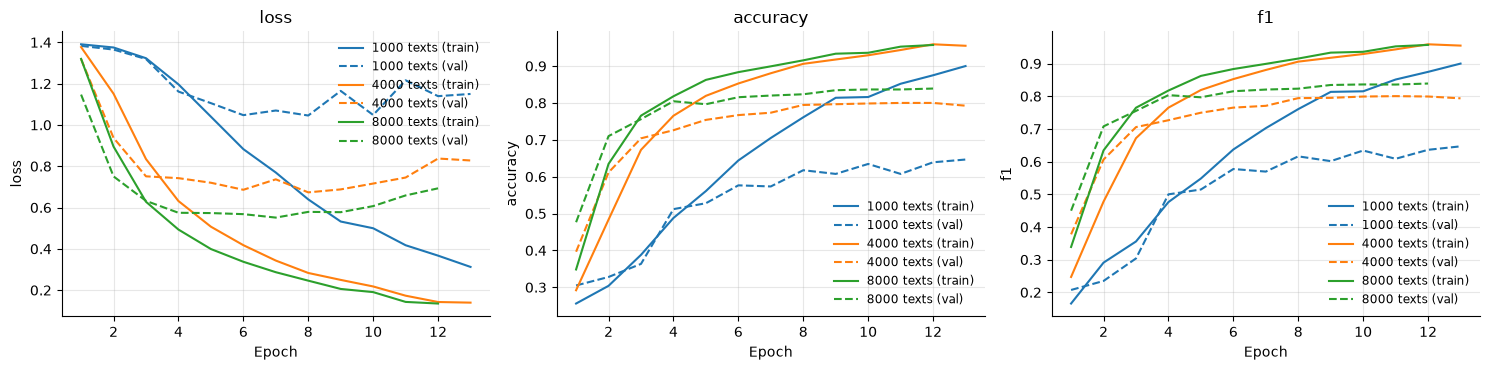

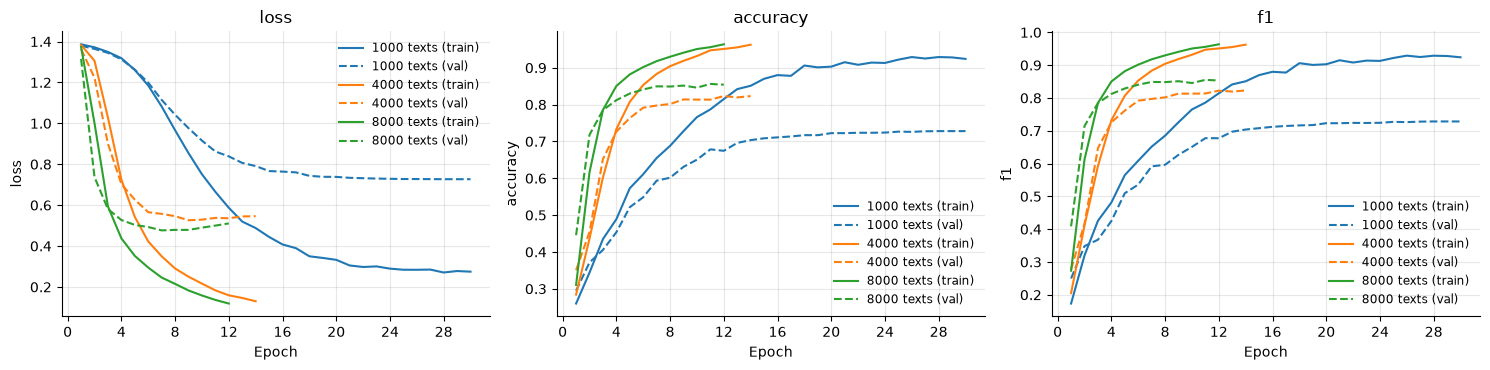

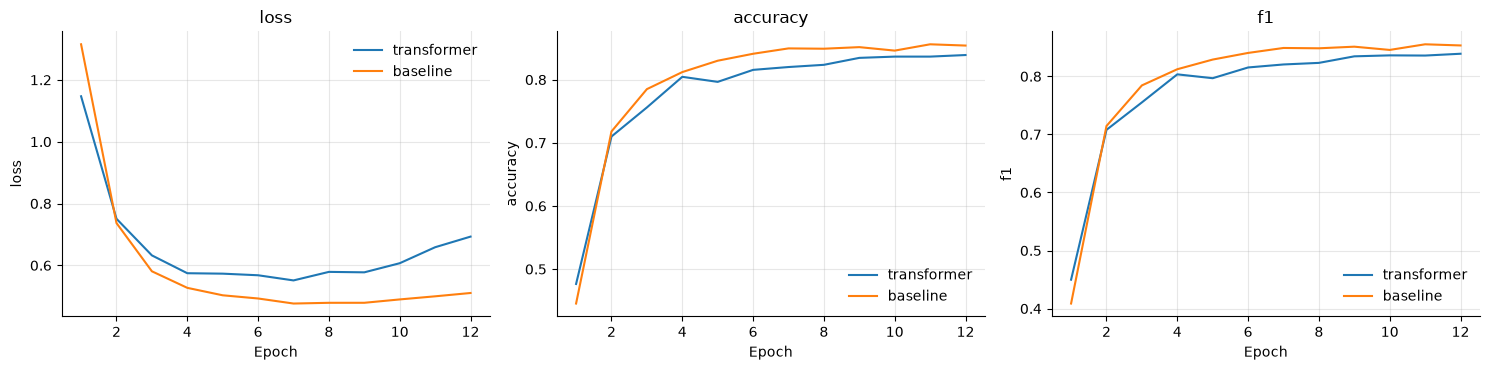

In [10]:
def pick(model_name: str, size: int, seed: int = SEED) -> RunResult:
    return next(result for result in results if (result.model, result.size, result.seed) == (model_name, size, seed))


for model_name in MODELS:
    histories = {f"{size} texts": pick(model_name, size).history for size in TRAIN_SIZES}
    saver.save(plot_comparison(histories, ["loss", "accuracy", "f1"], splits=("train", "val")), f"curves_{model_name}")

histories = {model_name: pick(model_name, TRAIN_SIZES[-1]).history for model_name in MODELS}
saver.save(plot_comparison(histories, ["loss", "accuracy", "f1"]), "transformer_vs_baseline");

In [11]:
runs = pd.DataFrame([
    {
        "model": result.model,
        "train size": result.size,
        "seed": result.seed,
        "vocabulary": len(result.encoder.vocabulary),
        "parameters": sum(p.numel() for p in result.task.model.parameters()),
        "epochs": result.history.series("val/loss")[0][-1],
        "best epoch": result.best_epoch,
        "best val loss": result.history.best("val/loss", "min")[1],
        "test loss": result.test["loss"],
        "test accuracy": result.test["accuracy"],
        "test precision": result.test["precision"],
        "test recall": result.test["recall"],
        "test f1": result.test["f1"],
        "training time, s": result.seconds,
    }
    for result in results
])
runs.to_csv(saver.directory / "runs.csv", index=False)

summary = runs.groupby(["model", "train size"])[
    ["test accuracy", "test f1", "best val loss", "best epoch", "training time, s"]
].agg(["mean", "std"])
summary.to_csv(saver.directory / "summary.csv")
summary.round(4)

test accuracy         test f1         best val loss  \
                                mean     std    mean     std          mean   
model       train size                                                       
baseline    1000              0.7236  0.0066  0.7231  0.0062        0.7506   
            4000              0.8186  0.0030  0.8184  0.0032        0.5296   
            8000              0.8462  0.0049  0.8460  0.0051        0.4780   
transformer 1000              0.6113  0.0134  0.6058  0.0174        1.0568   
            4000              0.7792  0.0060  0.7791  0.0058        0.6722   
            8000              0.8223  0.0021  0.8220  0.0016        0.5594   

                               best epoch         training time, s          
                           std       mean     std             mean     std  
model       train size                                                      
baseline    1000        0.0283    29.0000  0.0000           9.2493  0.0281  
            4000        0.0038     9.0000  0.0000          11.8157  0.0355  
            8000        0.0151     7.0000  0.0000          18.8099  0.0654  
transformer 1000        0.0171     7.6667  0.5774           7.5706  0.9970  
            4000        0.0144     7.0000  1.0000          20.9081  1.7890  
            8000        0.0197     6.3333  0.5774          38.7142  1.9350

test accuracy                                     test f1  \
model           baseline transformer transformer - baseline baseline   
train size                                                             
1000              0.7236      0.6113                -0.1122   0.7231   
4000              0.8186      0.7792                -0.0394   0.8184   
8000              0.8462      0.8223                -0.0239   0.8460   

                                               
model      transformer transformer - baseline  
train size                                     
1000            0.6058                -0.1173  
4000            0.7791                -0.0392  
8000            0.8220                -0.0240

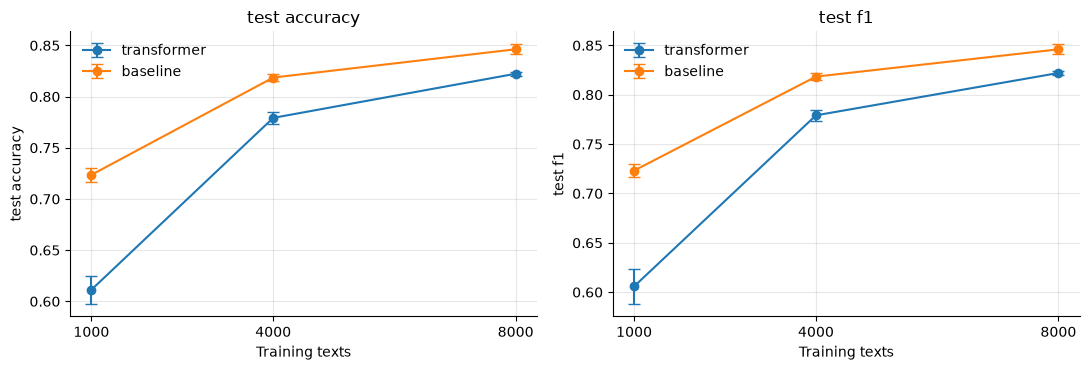

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, metric in zip(axes, ["test accuracy", "test f1"]):
    for model_name in MODELS:
        stats = runs[runs["model"] == model_name].groupby("train size")[metric].agg(["mean", "std"])
        ax.errorbar(stats.index, stats["mean"], yerr=stats["std"], marker="o", capsize=4, label=model_name)
    ax.set_xticks(TRAIN_SIZES)
    ax.set_xlabel("Training texts")
    ax.set_ylabel(metric)
    ax.set_title(metric)
    ax.legend()
fig.tight_layout()
saver.save(fig, "data_size_effect")

comparison = runs.pivot_table(index="train size", columns="model", values=["test accuracy", "test f1"], aggfunc="mean")
for metric in ["test accuracy", "test f1"]:
    comparison[(metric, "transformer - baseline")] = comparison[(metric, "transformer")] - comparison[(metric, "baseline")]
comparison.sort_index(axis=1).round(4)

,precision,recall,support
World,0.8635,0.7689,1900
Sports,0.8799,0.9021,1900
Business,0.7331,0.8426,1900
Sci/Tech,0.8209,0.7674,1900


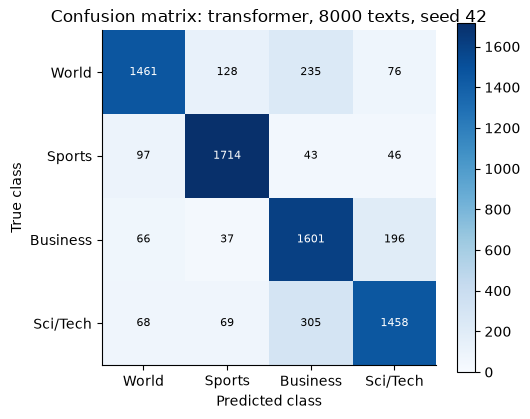

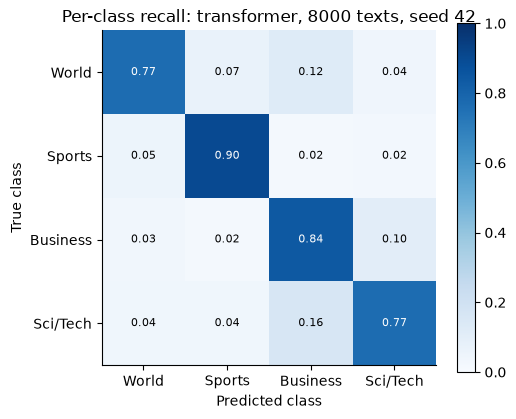

In [13]:
best = pick("transformer", TRAIN_SIZES[-1])
probs, targets = best.task.predict(make_loader(test_dataset, test_indices, best.encoder))
preds = probs.argmax(dim=1)
title = f"transformer, {best.size} texts, seed {best.seed}"

matrix = confusion_matrix(preds, targets, num_classes=len(class_names))
saver.save(plot_confusion_matrix(matrix, class_names, title=f"Confusion matrix: {title}"), "confusion_counts")
saver.save(plot_confusion_matrix(matrix, class_names, normalize=True, title=f"Per-class recall: {title}"), "confusion_normalized")

num_classes = len(class_names)
pd.DataFrame(
    {
        "precision": MulticlassPrecision(num_classes=num_classes, average=None)(preds, targets).numpy(),
        "recall": MulticlassRecall(num_classes=num_classes, average=None)(preds, targets).numpy(),
        "support": matrix.sum(dim=1).numpy(),
    },
    index=class_names,
).round(4)

In [14]:
errors = (preds != targets).nonzero().flatten()
order = probs[errors, preds[errors]].argsort(descending=True)
print(f"Errors: {len(errors)} of {len(targets)}")
for index in errors[order][:ERRORS_SHOWN].tolist():
    print(f"[{class_names[targets[index]]} -> {class_names[preds[index]]}, p = {probs[index, preds[index]]:.2f}] {test_dataset.texts[index]}")

Errors: 1366 of 7600
[World -> Sports, p = 1.00] Argentina Beats U.S. Men's Basketball Team Argentina defeated the United States team of National Basketball Association stars 89-81 here Friday in the Olympic semi-finals, dethroning the three-time defending champions.
[World -> Sports, p = 1.00] Ryder Cup: Europe close on victory Another good day at Oakland Hills sees Europe move 11-5 clear of the USA going into Sunday's Ryder Cup singles.
[World -> Sports, p = 1.00] Tennis: Davenport to play on Lindsay Davenport says she plans to play in the Australian Open next January.
[World -> Sports, p = 1.00] Dream Team Leads Spain 44-42 at Halftime ATHENS, Greece - As expected, the U.S. men's basketball team had its hands full in a quarterfinal game against Spain on Thursday...
[World -> Sports, p = 1.00] Tennis: Night final for Aus Open The centenary Australian Open will be the first Grand Slam event to stage its final at night.
[World -> Sports, p = 1.00] Dodgers Nip Giants 3-2 in Crucial Seri

[World -> Business, p = 0.79] Terreblanche challenges SA arrest White supremacist Eugene Terreblanche is detained after allegedly breaking the terms of his parole.
[Sports -> Sports, p = 0.99] Starting for Cardinals Has Privileges St. Louis is a collection of superstar position players and anonymous pitchers.
[Business -> Business, p = 0.98] Surviving Biotech's Downturns Charly Travers offers advice on withstanding the volatility of the biotech sector.
[Sci/Tech -> Sci/Tech, p = 0.98] IBM Chips May Someday Heal Themselves New technology applies electrical fuses to help identify and repair faults.


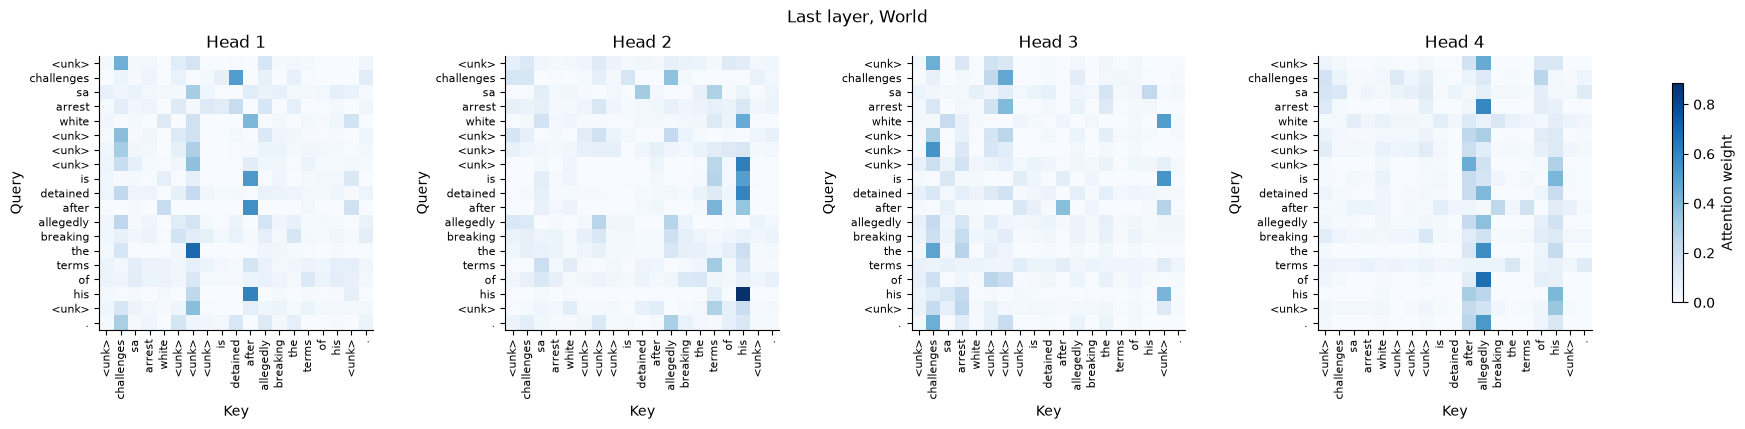

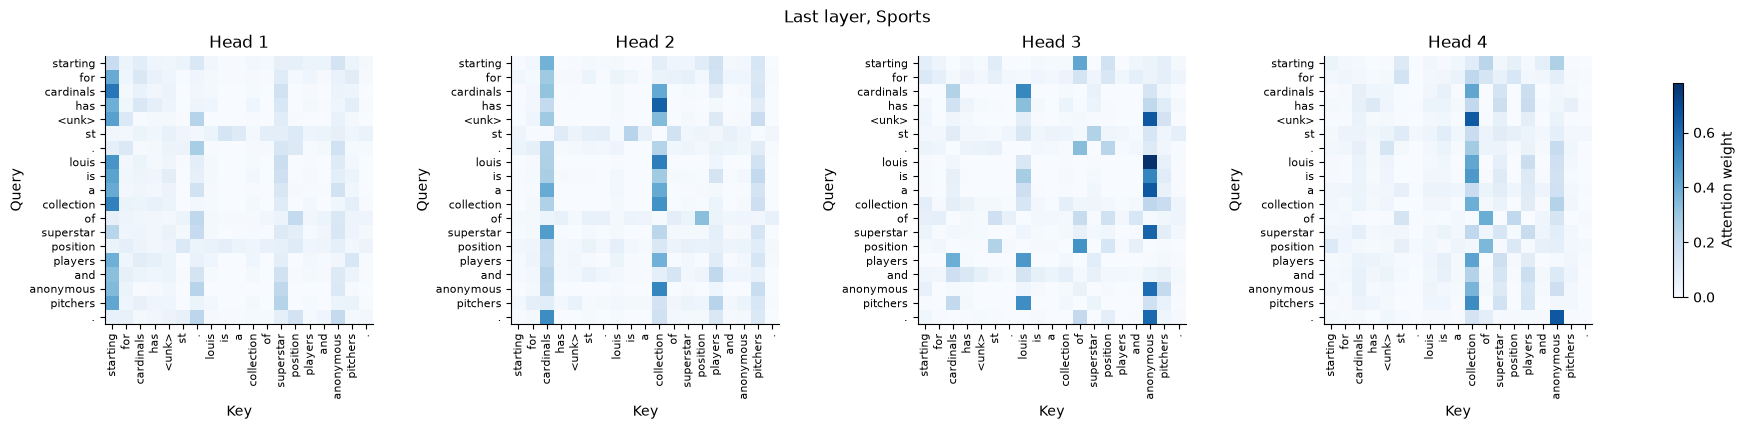

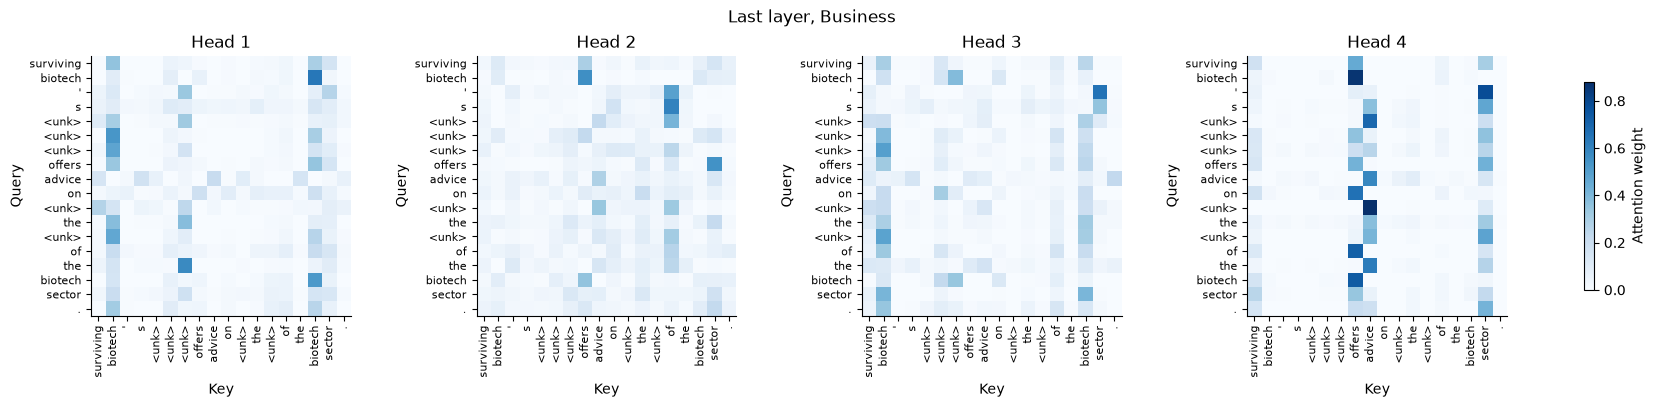

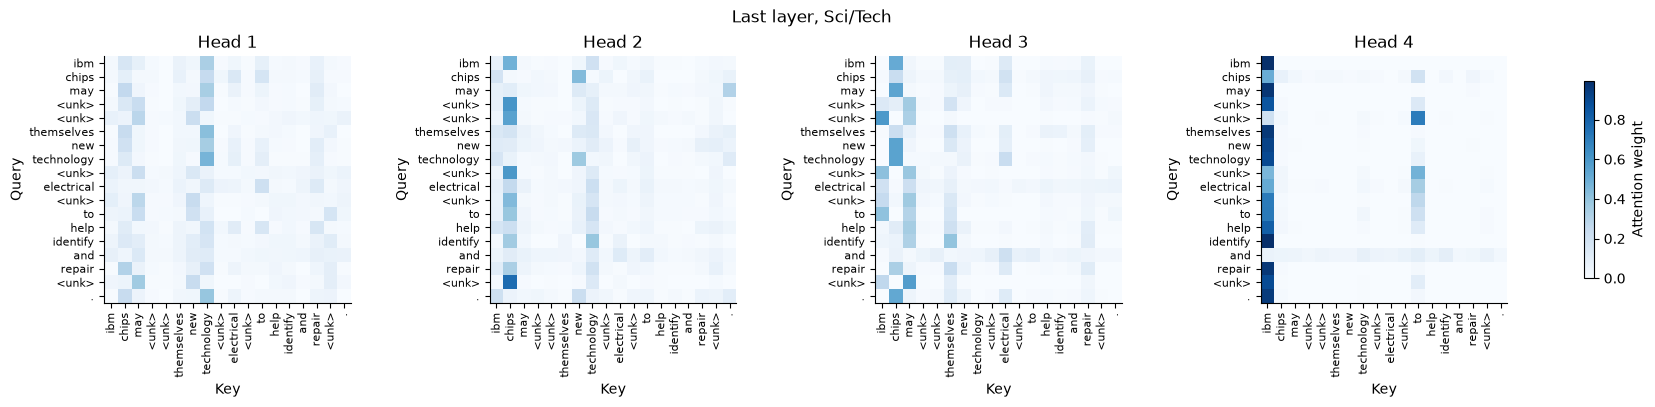

In [15]:
model = best.task.model.eval()
device = next(model.parameters()).device
heads = [f"Head {head + 1}" for head in range(NUM_HEADS)]


def first_short(label: int) -> int:
    return next(
        index
        for index, (text, target) in enumerate(zip(test_dataset.texts, test_dataset.labels))
        if target == label and len(tokenizer(text)) <= ATTENTION_TOKENS
    )


@torch.no_grad()
def attention_of(index: int) -> tuple[list[str], torch.Tensor, tuple[torch.Tensor, ...]]:
    ids = best.encoder(test_dataset.texts[index])
    logits, maps = model.forward_with_attention(ids.unsqueeze(0).to(device))
    return best.encoder.vocabulary.decode(ids.tolist()), logits.softmax(dim=-1)[0].cpu(), maps


attention_examples = [first_short(label) for label in range(len(class_names))]
for label, index in enumerate(attention_examples):
    tokens, class_probs, maps = attention_of(index)
    predicted = int(class_probs.argmax())
    print(f"[{class_names[label]} -> {class_names[predicted]}, p = {class_probs[predicted]:.2f}] {test_dataset.texts[index]}")

    fig = plot_attention(maps[-1][0], tokens, heads)
    fig.suptitle(f"Last layer, {class_names[label]}")
    slug = re.sub(r"\W+", "_", class_names[label]).lower()
    saver.save(fig, f"attention_{slug}")

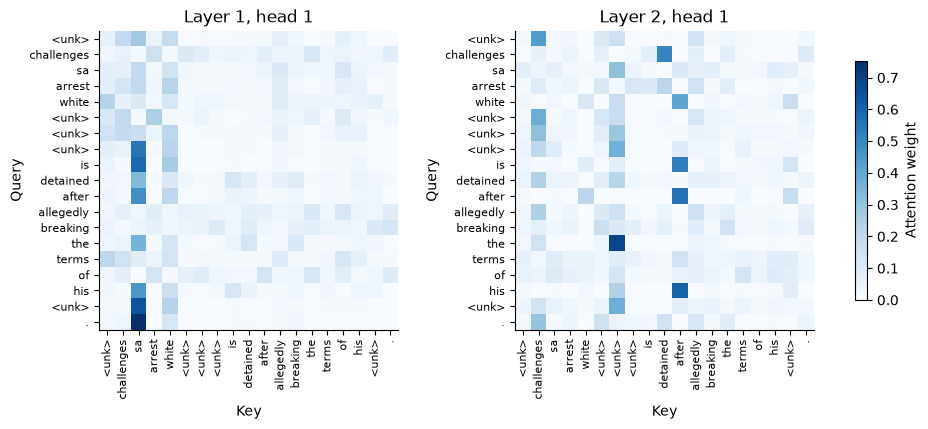

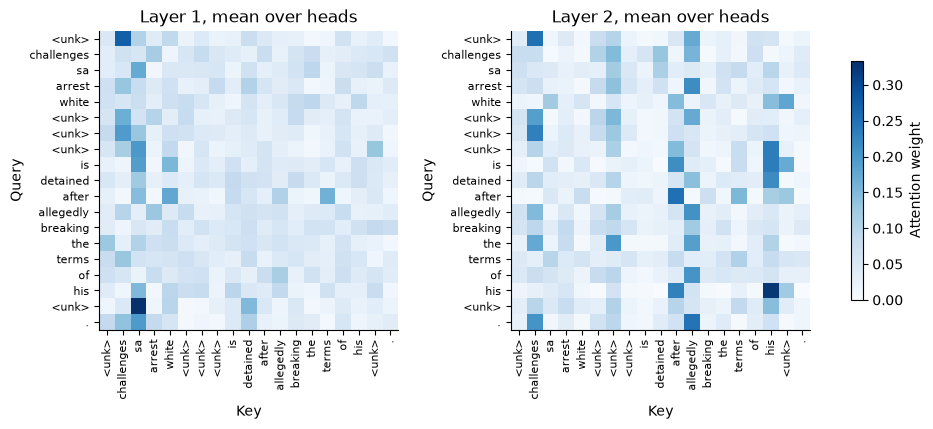

In [16]:
tokens, _, maps = attention_of(attention_examples[0])
layers = [f"Layer {layer + 1}" for layer in range(len(maps))]

saver.save(plot_attention(torch.stack([m[0, 0] for m in maps]), tokens, [f"{name}, head 1" for name in layers]), "attention_layers_head1")
saver.save(plot_attention(torch.stack([m[0].mean(dim=0) for m in maps]), tokens, [f"{name}, mean over heads" for name in layers]), "attention_layers_mean");